## Лабораторная работа №3. Кластеризация

Цель работы: изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

Постановка задачи:
1. Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.

5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.



## Импорт библиотек

In [200]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import shapiro, skew
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score,
    jaccard_score
)

from sklearn.feature_selection import mutual_info_classif, f_classif

from scipy.spatial.distance import cdist

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

## Загрузка датасета

In [201]:
df = pd.read_csv('iris.csv')

print("Первые пять строк датасета:")
display(df.head())

print("Размерность датасета:", df.shape)

print("\nИнформация о датасете:")
df.info()

print("\nКоличество пропусков:")
print(df.isnull().sum())

print("\nСтатистическое описание:")
display(df.describe())

Первые пять строк датасета:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Размерность датасета: (150, 5)

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Количество пропусков:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Статистическое описание:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Описание датасета

Для проведения кластеризации и анализа был использован классический набор данных Iris. Датасет содержит 150 наблюдений.
Каждый объект описывается четырьмя числовыми признаками, измеренными в сантиметрах:
* sepal_length — длина чашелистика;
* sepal_width — ширина чашелистика;
* petal_length — длина лепестка;
* petal_width — ширина лепестка.

Также в датасете присутствует один категориальный признак species, содержащий истинную видовую принадлежность объекта. В рамках задачи кластеризации этот признак не используется алгоритмами для построения моделей, а применяется исключительно для последующей оценки качества кластеризации с помощью внешних метрик.

Первичный анализ и качество данных

При дескриптивном анализе было установлено, что все числовые признаки имеют тип данных float64. Датасет является полностью чистым: пропуски (NaN-значения) во всех столбцах отсутствуют. Однако при проверке на дубликаты было выявлено наличие повторяющихся строк, которые были удалены на этапе предобработки (итоговый размер очищенной выборки составил 147 объектов).
Согласно описательным статистикам, средние значения признаков составляют: длина чашелистика — 5.84 см, ширина чашелистика — 3.05 см, длина лепестка — 3.76 см, ширина лепестка — 1.20 см. При этом признаки существенно различаются по своему разбросу: стандартное отклонение длины лепестка (1.76 см) более чем в 4 раза превышает стандартное отклонение ширины чашелистика (0.43 см), что в дальнейшем обосновывает необходимость обязательной стандартизации данных перед применением метрических алгоритмов кластеризации.

## Первичный анализ данных

Числовые признаки:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

Количество объектов каждого вида:
species
versicolor    50
virginica     49
setosa        48
Name: count, dtype: int64

Типы данных:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

Количество пропусков: 0
Количество дубликатов: 0


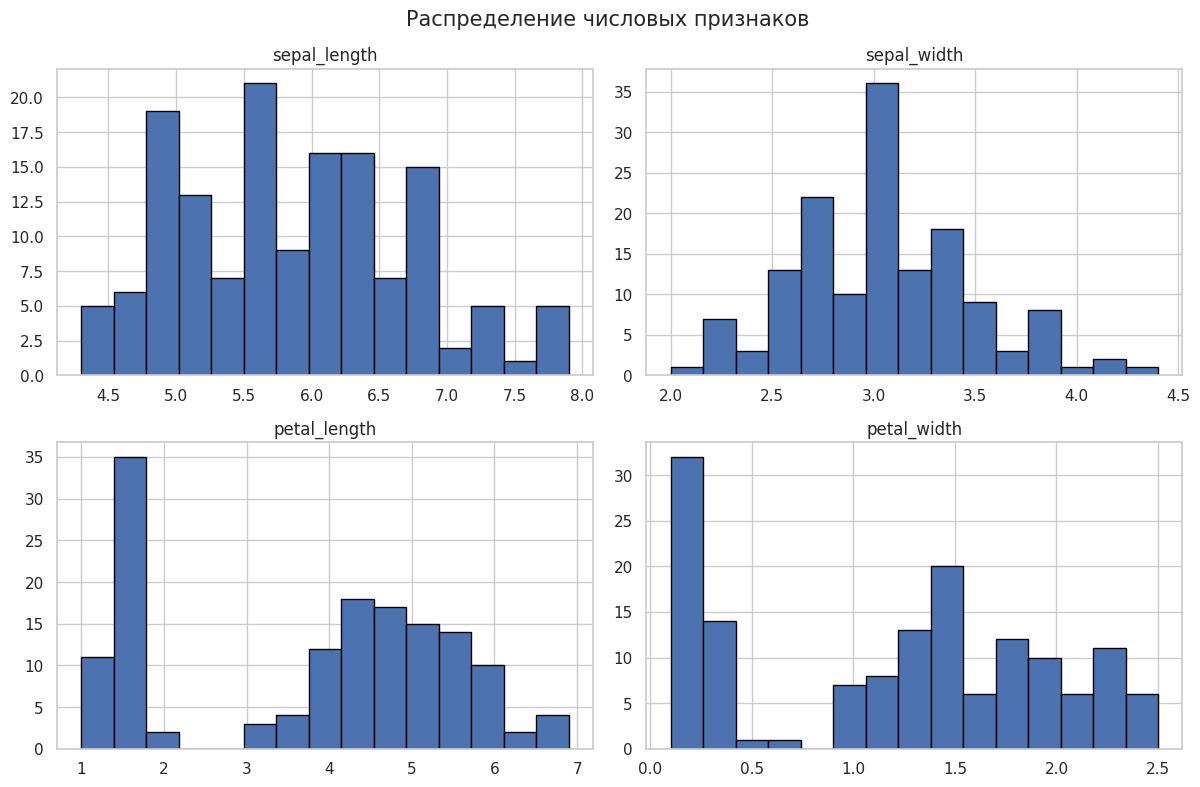


Тест Шапиро-Уилка: 



,Признак,P-value,Вывод (α=0.05)
0,sepal_length,1.6456e-02,Отличается от нормального
1,sepal_width,8.9130e-02,Нормальное распределение
2,petal_length,1.2971e-09,Отличается от нормального
3,petal_width,2.8810e-08,Отличается от нормального


In [202]:
df = df.drop_duplicates().dropna().reset_index(drop=True)

X = df.drop('species', axis=1)
y = df['species']

print("Числовые признаки:")
print(X.columns.tolist())

print("\nКоличество объектов каждого вида:")
print(y.value_counts())

print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество пропусков:", df.isna().sum().sum())
print("Количество дубликатов:", df.duplicated().sum())

X.hist(
    bins=15,
    figsize=(12, 8),
    edgecolor='black'
)

plt.suptitle('Распределение числовых признаков', fontsize=15)
plt.tight_layout()
plt.show()

print("\nТест Шапиро-Уилка: \n")

alpha = 0.05
normality_results = []

for column in X.columns:
    stat, p_value = shapiro(X[column])

    conclusion = "Нормальное распределение" if p_value > alpha else "Отличается от нормального"

    normality_results.append({
        'Признак': column,
        'P-value': f"{p_value:.4e}",
        'Вывод (α=0.05)': conclusion
    })

normality_df = pd.DataFrame(normality_results)
display(normality_df)


Визуальный анализ гистограмм числовых признаков показал, что распределение большинства переменных существенно отличается от нормального, при этом ключевыми индикаторами отклонения выступают выраженная асимметрия и наличие многовершинности. В частности, признак sepal_length демонстрирует бимодальную структуру с двумя отчетливыми пиками в районах 4.8–5.0 и 5.5–5.8, что делает кривую распределения не согласующейся с нормальным распределением, а признак sepal_width обладает положительной асимметрией и несимметричными хвостами, что не позволяет однозначно принять гипотезу о нормальности. Распределение petal_length характеризуется четко выраженной бимодальностью с двумя крупными пиками (в области 1–2 см и 4–6 см), а признак petal_width демонстрирует сильную правостороннюю асимметрию с длинным хвостом вправо и пиком, смещенным к нулю, что также подтверждает мультимодальный характер данных и высокий эксцесс.

Дубликаты и пропуски были удалены из выборки.

## Проверка выбросов

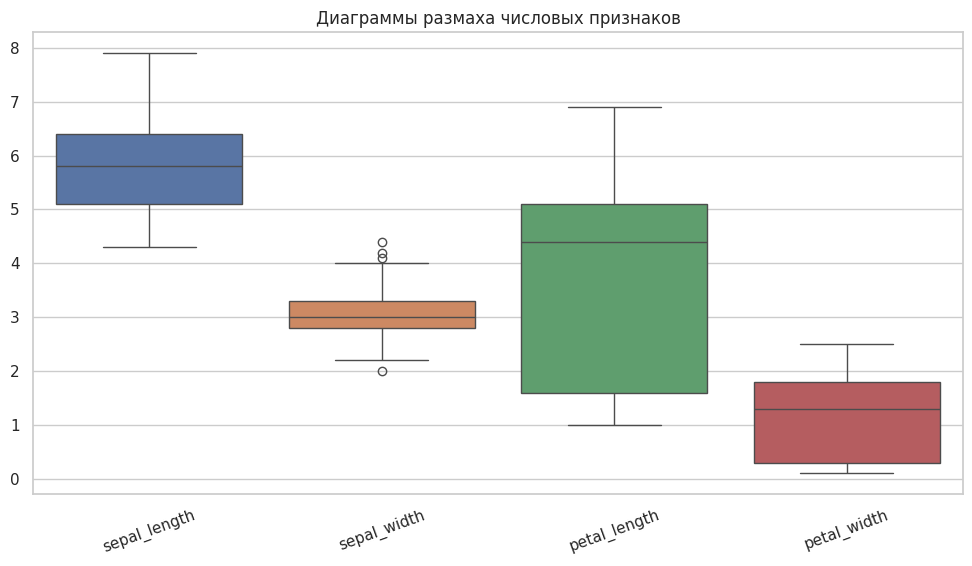

Количество выбросов по методу IQR:

sepal_length: 0
sepal_width: 4
petal_length: 0
petal_width: 0


In [203]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=X)
plt.title('Диаграммы размаха числовых признаков')
plt.xticks(rotation=20)
plt.show()

print("Количество выбросов по методу IQR:\n")

for column in X.columns:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = X[
        (X[column] < lower) |
        (X[column] > upper)
    ]

    print(f"{column}: {len(outliers)}")

Признаки измерены в одних единицах, но существенно различаются по масштабу и разбросу: межквартильный размах длины лепестка примерно в семь раз больше, чем у ширины чашелистика. Без приведения к общему масштабу признаки с большими значениями будут доминировать в евклидовом расстоянии и в градиентных обновлениях, поэтому стандартизация обязательна.

## Оценка информационной значимости признаков

In [204]:
f_values, p_values = f_classif(X, y)

anova = pd.DataFrame({
    'Признак': X.columns,
    'F-статистика': f_values,
    'p-value': p_values
})

display(anova.sort_values(
    by='F-статистика',
    ascending=False
))

,Признак,F-статистика,p-value
2,petal_length,1132.387047,8.180546e-89
3,petal_width,915.183585,1.352973e-82
0,sepal_length,116.672939,7.530912e-31
1,sepal_width,47.869839,1.150338e-16


Для оценки значимости признаков применён однофакторный дисперсионный анализ (ANOVA F-тест), проверяющий нулевую гипотезу о равенстве средних значений признака во всех трёх классах: чем больше F-статистика, тем сильнее межгрупповые различия относительно внутригруппового разброса. Полученные p-value для всех четырёх признаков на порядки меньше стандартного уровня значимости 0.05 (максимальное — $ 1.3 \cdot 10^{-16} $ у ширины чашелистика), то есть нулевая гипотеза отвергается в каждом случае: ни один признак не является статистически незначимым, и все они разделяют виды.

# Проверка условий применения кластеризации.

Условия применимости кластеризации выполнены — целевая переменная не участвует в обучении, критических выбросов нет; данные пригодны для кластеризации после стандартизации, при этом ожидаемое число хорошо разделимых кластеров равно трём, так как в исходной выборке 3 класса.


## Стандартизация признаков

In [205]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("Стандартизированные данные:")
display(X_scaled.head())

print("\nСредние значения:")
print(X_scaled.mean().round(4))

print("\nСтандартные отклонения:")
print(X_scaled.std().round(4))

Стандартизированные данные:


,sepal_length,sepal_width,petal_length,petal_width
0,-0.915509,1.019971,-1.357737,-1.3357
1,-1.157560,-0.128082,-1.357737,-1.3357
2,-1.399610,0.331139,-1.414778,-1.3357
3,-1.520635,0.101529,-1.300696,-1.3357
4,-1.036535,1.249582,-1.357737,-1.3357



Средние значения:
sepal_length   -0.0
sepal_width     0.0
petal_length   -0.0
petal_width    -0.0
dtype: float64

Стандартные отклонения:
sepal_length    1.0034
sepal_width     1.0034
petal_length    1.0034
petal_width     1.0034
dtype: float64


MinMaxScaler был отклонён, так как он опирается на минимальные и максимальные значения и потому критически чувствителен к выбросам: четыре аномальных значения ширины чашелистика (2.0 и 4.1–4.4 см) задали бы границы диапазона и сжали основную массу наблюдений в узкий подынтервал, а новые объекты за пределами обучающего диапазона нарушили бы заданные границы. MaxAbsScaler предназначен для разреженных данных, которых здесь нет, а Normalizer нормирует строки, а не столбцы.

StandardScaler решает проблему несопоставимости признаков. В исходных данных признаки измерены в одних единицах, но имеют разный разброс: дисперсия длины лепестка более чем в 15 раз превышает дисперсию ширины чашелистика. В евклидовом расстоянии и в функции потерь доминируют признаки с большим разбросом, а узкие по масштабу признаки фактически игнорируются, хотя могут быть содержательно важны. Функция StandardScaler — устранить это искажение: он выражает каждое значение в числе стандартных отклонений от среднего по своему признаку, то есть переводит все измерения в единую безразмерную шкалу «насколько сильно объект отклоняется от типичного». Тем самым признакам придаётся равный вес при вычислении сходства.

## Матрица диаграмм рассеивания

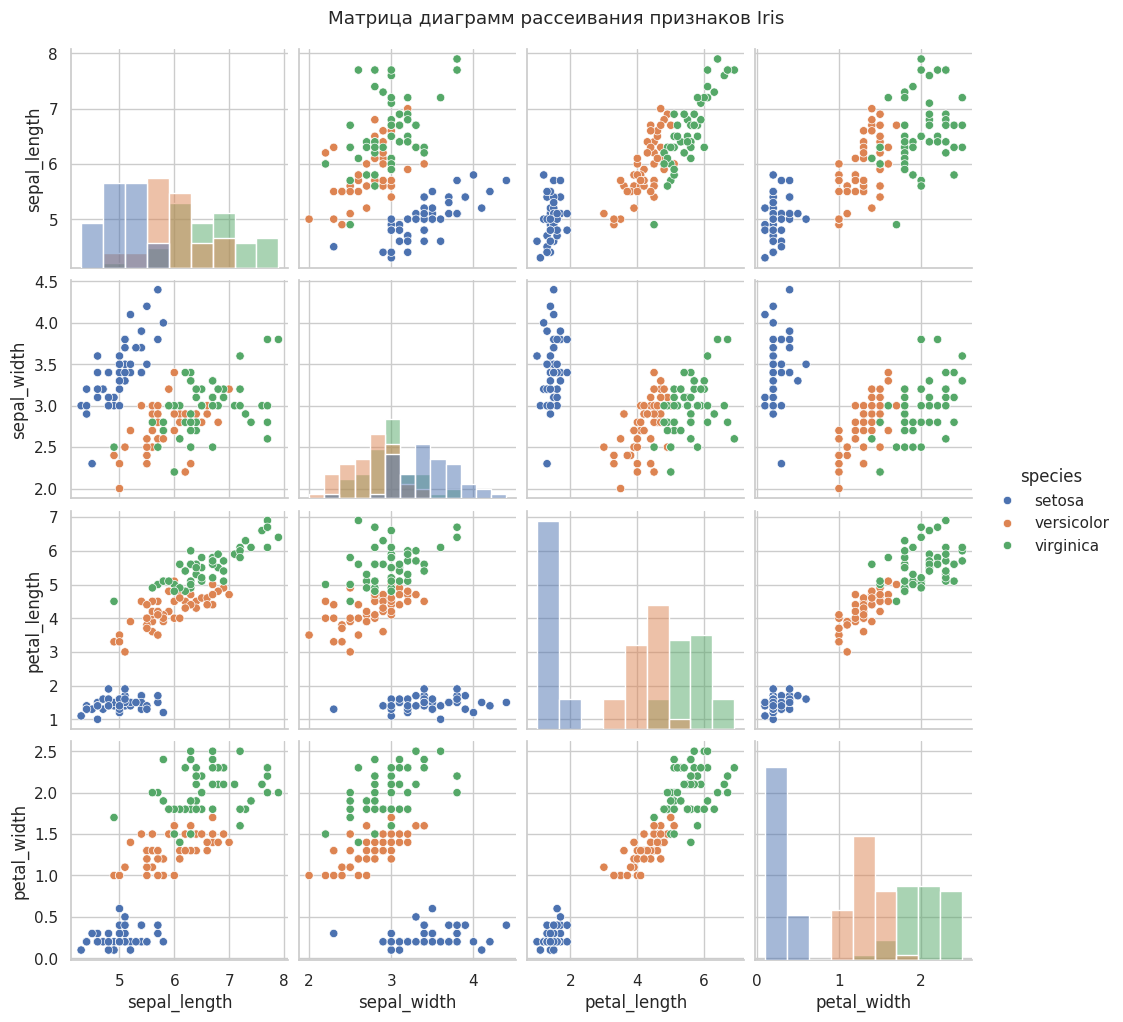

In [206]:
sns.pairplot(
    df,
    vars=X.columns,
    hue='species',
    diag_kind='hist'
)

plt.suptitle(
    'Матрица диаграмм рассеивания признаков Iris',
    y=1.02
)

plt.show()

Матрица диаграмм рассеивания показывает, что данные не являются однородным случайным облаком: во всех проекциях отчётливо выделяются обособленные сгущения точек, разделённые зонами пониженной плотности. Наиболее ясно структура проявляется в проекциях с участием признаков лепестка. Здесь видна компактная, полностью изолированная группа объектов, сосредоточенная в области petal_length ≈ 1.0–1.9 см и petal_width ≈ 0.1–0.6 см, которая соответствует виду setosa; между ней и остальными наблюдениями существует пустой интервал (примерно 2–3 см по длине и 0.7–0.9 см по ширине лепестка), не содержащий ни одного объекта. Гистограммы на главной диагонали подтверждают это: распределения признаков лепестка отчётливо многомодальны, с узким высоким пиком в области малых значений и широким сгущением в области больших. Признаки чашелистика ведут себя иначе: их распределения унимодальны и близки к нормальным, а проекции с их участием дают диффузные облака с сильным перекрытием классов, что указывает на их слабую разделяющую способность.

Предположительное количество кластеров оценивается как два или три. Строго по геометрии данных надёжно выделяются два кластера: изолированная группа setosa и объединённое облако остальных наблюдений. Внутри второго облака угадываются два сгущения, соответствующие versicolor (petal_length ≈ 3.0–5.1 см, petal_width ≈ 1.0–1.8 см) и virginica (petal_length ≈ 4.5–6.9 см, petal_width ≈ 1.4–2.5 см), однако они соприкасаются и частично взаимно проникают: чёткой разделяющей полосы между ними нет, часть точек одного вида попадает в область другого. Таким образом, трёхкластерная структура содержательно обоснована, но её границы размыты, тогда как двухкластерное разбиение геометрически выражено значительно чётче — это согласуется с более высокими значениями силуэта при k = 2.
По типу кластерная структура является групповой (центроидной) с частичным перекрытием, а не ленточной, кольцевой или цепочечной. Кластеры имеют вытянутую эллипсоидальную форму, ориентированную преимущественно вдоль главной диагонали проекций, что обусловлено сильными положительными корреляциями признаков; ширина чашелистика, напротив, образует бесформенное облако и слабо связана с остальными признаками. Кластеры различаются по объёму и плотности: группа setosa мала по размаху и очень плотна, две другие — заметно более протяжённые и разреженные. Изолированных одиночных точек, удалённых от всех сгущений, на диаграммах не наблюдается: экстремальные значения ширины чашелистика (2.0 и 4.4 см) лежат на периферии собственного кластера setosa, а не вне структуры, что подтверждает решение не удалять их как ошибки.

Выявленная структура определяет выбор алгоритмов: компактные выпуклые сгущения без сложных нелинейных границ делают оправданным применение центроидных методов (k-means). Иерархическая кластеризация также применима и полезна для проверки числа групп по дендрограмме; необходимость в плотностных методах типа DBSCAN отсутствует, за исключением задачи маркировки периферийных точек как шума.

## Определение оптимального количества кластеров

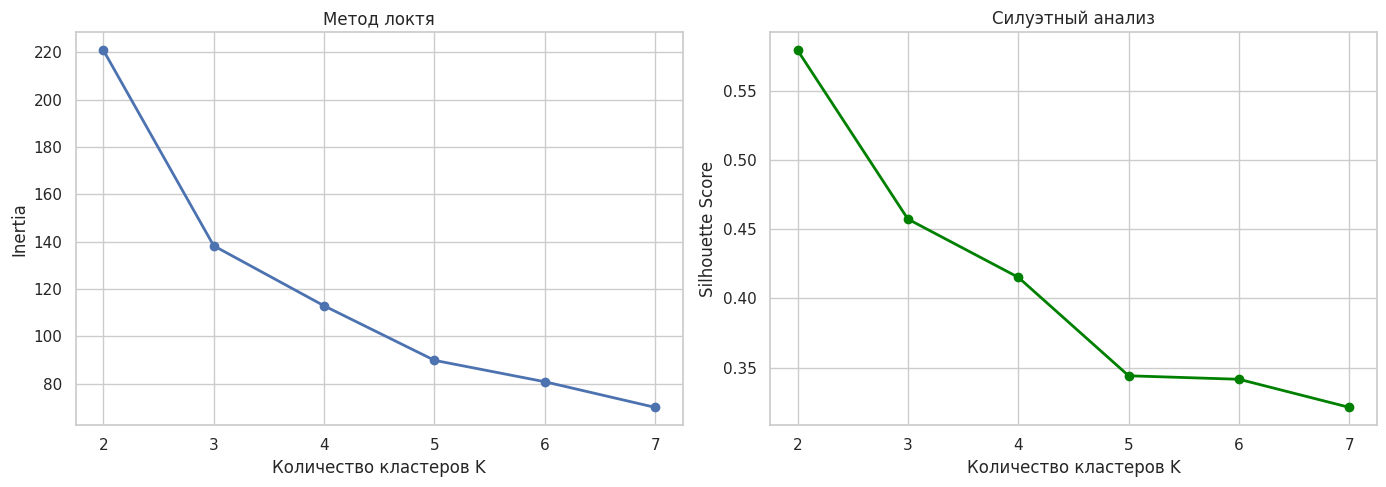

K=2: Inertia=220.86, Silhouette=0.5792
K=3: Inertia=138.26, Silhouette=0.4573
K=4: Inertia=112.91, Silhouette=0.4152
K=5: Inertia=89.89, Silhouette=0.3441
K=6: Inertia=80.84, Silhouette=0.3416
K=7: Inertia=70.01, Silhouette=0.3213


In [207]:
inertia = []
silhouette_scores = []

K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    list(K_range),
    inertia,
    marker='o',
    linewidth=2
)

axes[0].set_title('Метод локтя')
axes[0].set_xlabel('Количество кластеров K')
axes[0].set_ylabel('Inertia')
axes[0].set_xticks(list(K_range))
axes[0].grid(True)

axes[1].plot(
    list(K_range),
    silhouette_scores,
    marker='o',
    linewidth=2,
    color='green'
)

axes[1].set_title('Силуэтный анализ')
axes[1].set_xlabel('Количество кластеров K')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(K_range))
axes[1].grid(True)

plt.tight_layout()
plt.show()

for k, inertia_value, silhouette_value in zip(
    K_range,
    inertia,
    silhouette_scores
):
    print(
        f"K={k}: "
        f"Inertia={inertia_value:.2f}, "
        f"Silhouette={silhouette_value:.4f}"
    )

По результатам проверки предполагаемого количества кластеров можно сделать вывод, что разыне метрики предполагают разное оптимальное количество кластеров (3 у метода локтя и 2 у силуэта). Таким образом, будет проведена проверка с количеством кластеров равным 2 и 3.

## Кластеризация методом K-means

Алгоритм K-means чувствителен к выбору начального положения центроидов, так как он может сходиться к локальным минимумам целевой функции (инерции). Параметр n_init=10 означает, что алгоритм будет запущен 10 раз с различными случайными начальными центрами, а в качестве итогового решения будет выбран вариант с наименьшим значением инерции.

Параметр random_state=42 установлен для детерминированности вычислений в методе K-means. Это гарантирует, что при повторном запуске кода результаты инициализации центроидов будут идентичны, обеспечивая полную воспроизводимость эксперимента и полученных метрик качества.

Количество объектов в каждом кластере:
KMeans_cluster
0    48
1    99
Name: count, dtype: int64


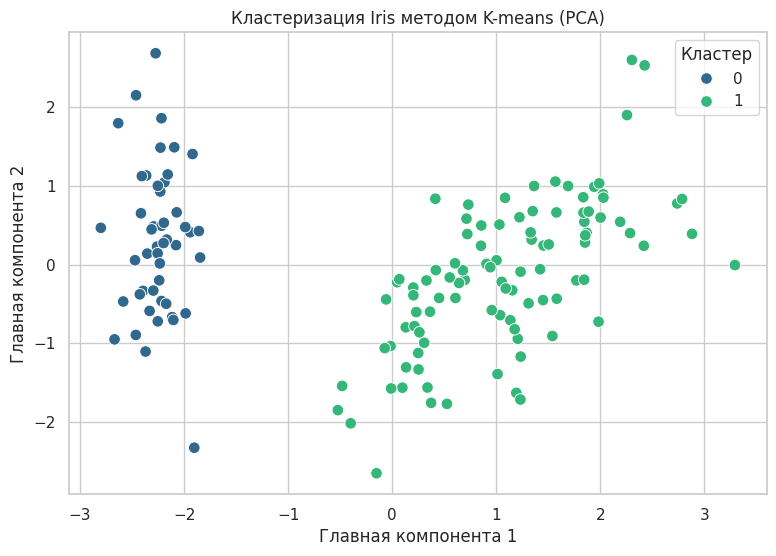

Объяснённая дисперсия PCA: 0.9577


In [208]:
kmeans_2 = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)

kmeans_labels_2 = kmeans_2.fit_predict(X_scaled)

df['KMeans_cluster'] = kmeans_labels_2

print("Количество объектов в каждом кластере:")
print(df['KMeans_cluster'].value_counts().sort_index())

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=kmeans_labels_2,
    palette='viridis',
    s=70
)

plt.title('Кластеризация Iris методом K-means (PCA)')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.legend(title='Кластер')
plt.show()

print(
    "Объяснённая дисперсия PCA:",
    pca.explained_variance_ratio_.sum().round(4)
)

Количество объектов в каждом кластере:
KMeans_cluster
0    52
1    48
2    47
Name: count, dtype: int64


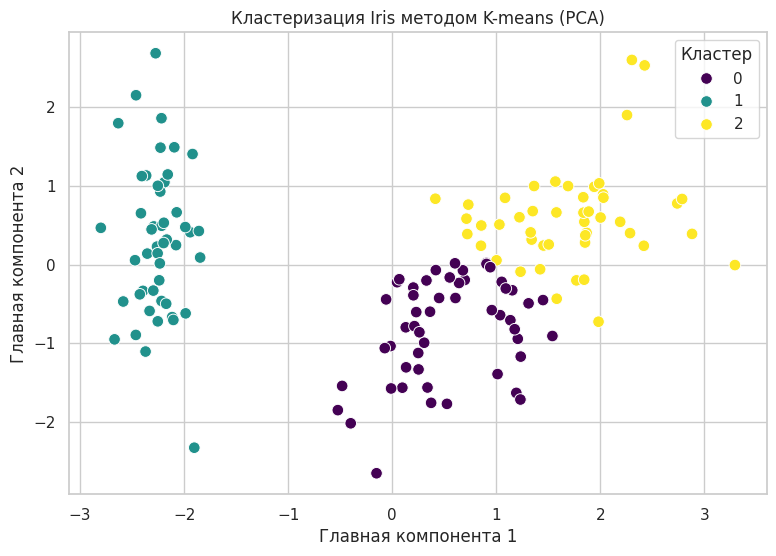

Объяснённая дисперсия PCA: 0.9577


In [209]:
kmeans_3 = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

kmeans_labels_3 = kmeans_3.fit_predict(X_scaled)

df['KMeans_cluster'] = kmeans_labels_3

print("Количество объектов в каждом кластере:")
print(df['KMeans_cluster'].value_counts().sort_index())

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=kmeans_labels_3,
    palette='viridis',
    s=70
)

plt.title('Кластеризация Iris методом K-means (PCA)')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.legend(title='Кластер')
plt.show()

print(
    "Объяснённая дисперсия PCA:",
    pca.explained_variance_ratio_.sum().round(4)
)

Проекция стандартизированных данных на первые две главные компоненты, объясняющие около 96 % суммарной дисперсии, позволяет содержательно оценить полученные разбиения при k = 2 и k = 3. В обоих вариантах устойчиво выделяется компактный, плотный и полностью обособленный кластер, занимающий левую часть плоскости: он соответствует объектам с малыми размерами лепестка (вид setosa) и подтверждает вывод матрицы диаграмм рассеивания о наличии пустой зоны между этой группой и остальной выборкой.

При k = 2 все остальные объекты объединяются во второй кластер — единое вытянутое облако, ориентированное вдоль первой главной компоненты. Это разбиение геометрически почти идеально: кластеры не перекрываются, граница проходит через зону пониженной плотности, чем объясняются максимальное значение коэффициента силуэта (0.5802) и inertia 223.73. Содержательно, однако, такое разбиение игнорирует внутреннюю неоднородность правого облака, объединяя объекты двух видов (versicolor и virginica) в одну группу, то есть описывает структуру лишь на уровне крупной гранулярности.

При k = 3 правое облако разделяется на два кластера, тогда как кластер setosa сохраняется без изменений. Это разбиение согласуется с методом локтя: наибольшее падение inertia наблюдается именно при переходе от k = 2 к k = 3 (223.73 → 140.97), после чего кривая выходит на плато. Одновременно граница между новыми кластерами оказывается размытой: в центральной части облака наблюдается взаимное проникновение точек, отдельные объекты одного кластера лежат внутри сгущения другого. По этой причине силуэт снижается до 0.4590.

## Иерархическая кластеризация

Для иерархической кластеризации был выбран метод Уорда (ward). Данный метод минимизирует дисперсию внутри объединяемых кластеров на каждом шаге агломерации. Выбор метода Уорда обоснован следующими факторами:
* Он стремится формировать кластеры одинакового размера и сферической формы, что концептуально близко к целевой функции метода K-means (минимизация суммы квадратов расстояний). Это делает корректным прямое сравнение результатов двух алгоритмов.
* Метод Уорда хорошо работает с евклидовым расстоянием, которое использовалось при стандартизации данных (StandardScaler).
* Он менее чувствителен к шуму и выбросам по сравнению с методами одиночной или полной связи (single/complete linkage), и позволяет получать более сбалансированные дендрограммы.

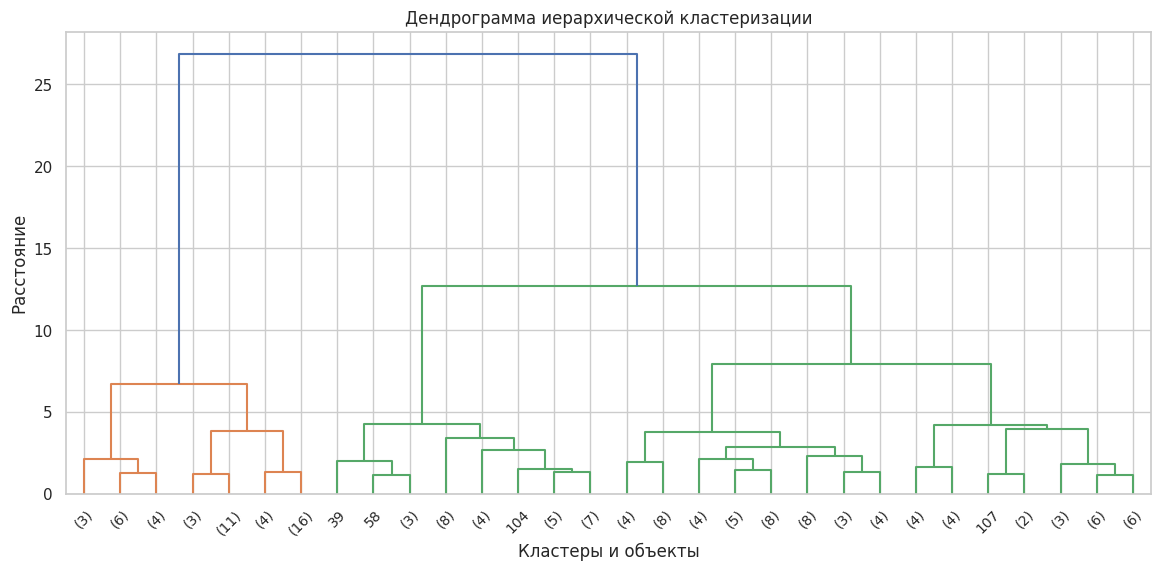

In [210]:
Z = linkage(
    X_scaled,
    method='ward'
)

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30
)

plt.title('Дендрограмма иерархической кластеризации')
plt.xlabel('Кластеры и объекты')
plt.ylabel('Расстояние')
plt.show()

Анализ дендрограммы, построенной с использованием метода Уорда и усечения lastp=30, наглядно демонстрирует иерархическую структуру данных. На графике отчётливо виден самый высокий уровень объединения на расстоянии около 27 единиц, который разделяет всю выборку на два крупных кластера: обособленную группу слева (оранжевый цвет, ~50 объектов) и объединённое облако справа (зелёный цвет, ~97 объектов). Это полностью согласуется с результатами метода K-means при k=2 и подтверждает наличие в данных двух фундаментально различных групп (вид setosa и объединённые versicolor/virginica). Внутри правого кластера наблюдается следующее значимое ветвление на уровне расстояния около 12–13 единиц, которое делит его на две подгруппы. Таким образом, дендрограмма визуально обосновывает выбор числа кластеров k=3 как биологически и геометрически значимого уровня разбиения.

Количество объектов в каждом кластере:
Hierarchical_cluster
0    100
1     47
Name: count, dtype: int64


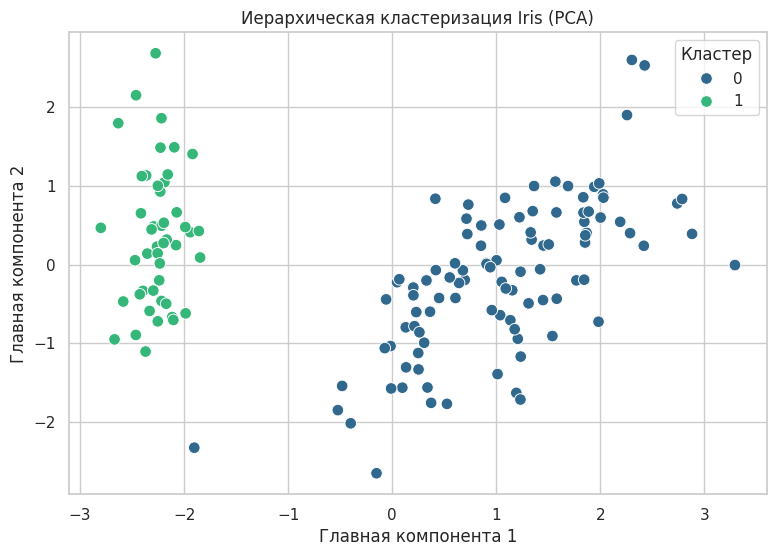

In [211]:
hierarchical_2 = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

hierarchical_labels_2 = hierarchical_2.fit_predict(X_scaled)

df['Hierarchical_cluster'] = hierarchical_labels_2

print("Количество объектов в каждом кластере:")
print(
    df['Hierarchical_cluster']
    .value_counts()
    .sort_index()
)


plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=hierarchical_labels_2,
    palette='viridis',
    s=70
)

plt.title('Иерархическая кластеризация Iris (PCA)')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.legend(title='Кластер')
plt.show()

Количество объектов в каждом кластере:
Hierarchical_cluster
0    70
1    47
2    30
Name: count, dtype: int64


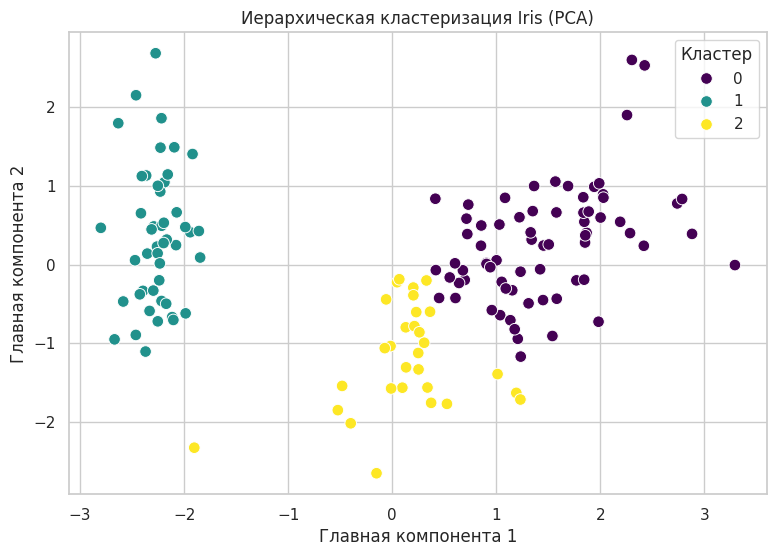

In [212]:
hierarchical_3 = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

hierarchical_labels_3 = hierarchical_3.fit_predict(X_scaled)

df['Hierarchical_cluster'] = hierarchical_labels_3

print("Количество объектов в каждом кластере:")
print(
    df['Hierarchical_cluster']
    .value_counts()
    .sort_index()
)


plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=hierarchical_labels_3,
    palette='viridis',
    s=70
)

plt.title('Иерархическая кластеризация Iris (PCA)')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.legend(title='Кластер')
plt.show()

Визуализация результатов в пространстве главных компонент (PCA) для k=2 показывает идеальное разделение данных: компактный кластер 1 (зелёный) полностью изолирован от протяжённого кластера 0 (синий), граница между ними проходит через зону отсутствия точек, что свидетельствует о высокой устойчивости такого разбиения. При увеличении числа кластеров до k=3 структура усложняется: левая группа сохраняется без изменений (кластер 1, бирюзовый), тогда как правое облако разделяется на кластер 0 (фиолетовый) и кластер 2 (жёлтый). В отличие от K-means, где граница между двумя правыми видами проходила скорее поперёк вытянутого облака, иерархический метод с методом Уорда (минимизирующим внутрикластерную дисперсию) выделил кластер 2 как более плотную нижнюю часть этого облака, оставив в кластере 0 верхнюю, более разреженную часть с несколькими выбросами в правом верхнем углу. Граница между кластерами 0 и 2 остаётся размытой, наблюдается взаимное проникновение точек в центральной части, что указывает на сложность линейного разделения видов versicolor и virginica в данном проекционном пространстве.

## Оценка качества кластеризации

In [213]:
def evaluate_clustering(X_data, labels, method_name):

    silhouette = silhouette_score(X_data, labels)

    calinski = calinski_harabasz_score(
        X_data,
        labels
    )

    davies = davies_bouldin_score(
        X_data,
        labels
    )

    return {
        'Метод': method_name,
        'Silhouette Score': silhouette,
        'Calinski-Harabasz': calinski,
        'Davies-Bouldin': davies
    }


results = []

results.append(
    evaluate_clustering(
        X_scaled,
        kmeans_labels_2,
        'K-means - 2 кластера'
    )
)

results.append(
    evaluate_clustering(
        X_scaled,
        kmeans_labels_3,
        'K-means - 3 кластера'
    )
)

results.append(
    evaluate_clustering(
        X_scaled,
        hierarchical_labels_2,
        'Hierarchical - 2 кластера'
    )
)

results.append(
    evaluate_clustering(
        X_scaled,
        hierarchical_labels_3,
        'Hierarchical - 3 кластера'
    )
)

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Метод,Silhouette Score,Calinski-Harabasz,Davies-Bouldin
0,K-means - 2 кластера,0.5792,241.0380,0.5961
1,K-means - 3 кластера,0.4573,234.2108,0.8324
2,Hierarchical - 2 кластера,0.5744,230.1508,0.5941
3,Hierarchical - 3 кластера,0.4465,216.8003,0.7989


Анализ внутренних метрик качества показывает высокую степень согласованности результатов, полученных методами K-means и иерархической кластеризации (метод Уорда), что подтверждает устойчивость выявленной структуры данных. При разбиении на два кластера оба алгоритма демонстрируют наилучшие показатели компактности и разделимости: коэффициент силуэта достигает максимальных значений (0.5792 для K-means и 0.5744 для иерархического метода), индекс Калински-Харабаса также максимален (241.04 и 230.15 соответственно), а индекс Дэвиса-Булдина, характеризующий отношение внутрикластерного разброса к межкластерному расстоянию, принимает минимальные значения (около 0.59). Это количественно подтверждает вывод о наличии в данных двух четко обособленных групп: компактного кластера вида setosa и объединенного облака видов versicolor и virginica.

При увеличении числа кластеров до трех наблюдается ожидаемое снижение качества разбиения по всем метрикам. Силуэтный коэффициент падает до 0.45–0.46, индекс Калински-Харабаса уменьшается, а индекс Дэвиса-Булдина возрастает до 0.80–0.83. Такое ухудшение метрик обусловлено тем, что алгоритмы вынуждены разделять единое вытянутое облако точек (versicolor и virginica) на две части, граница между которыми размыта, что приводит к увеличению внутрикластерных расстояний и снижению изолированности групп. Тем не менее, значения силуэта выше 0.4 свидетельствуют о том, что структура из трех кластеров все еще является различимой и содержательно обоснованной, соответствуя биологической классификации, несмотря на геометрическое перекрытие двух видов.
Сравнение методов показывает, что K-means незначительно превосходит иерархическую кластеризацию по значениям силуэта и индекса Калински-Харабаса как для двух, так и для трех кластеров. Однако при  k=3 иерархический метод показывает чуть лучшее (меньшее) значение индекса Дэвиса-Булдина (0.7989 против 0.8324 у K-means).

## Внешние метрики качества

In [214]:
def external_metrics(y_true, labels, method_name):

    return {
        'Метод': method_name,
        'Rand Index': rand_score(y_true, labels),
        'Adjusted Rand Index': adjusted_rand_score(
            y_true, labels
        ),
        'NMI': normalized_mutual_info_score(
            y_true, labels
        ),
        'Homogeneity': homogeneity_score(
            y_true, labels
        ),
        'Completeness': completeness_score(
            y_true, labels
        ),
        'V-measure': v_measure_score(
            y_true, labels
        )
    }


external_results = pd.DataFrame([
    external_metrics(y, kmeans_labels_2, 'K-means - 2 кластера'),
    external_metrics(y, kmeans_labels_3, 'K-means - 3 кластера'),
    external_metrics(y, hierarchical_labels_2, 'Hierarchical - 2 кластера'),
    external_metrics(y, hierarchical_labels_3, 'Hierarchical - 3 кластера')
])

display(external_results.round(4))

,Метод,Rand Index,Adjusted Rand Index,NMI,Homogeneity,Completeness,V-measure
0,K-means - 2 кластера,0.7717,0.5606,0.7302,0.5751,1.0000,0.7302
1,K-means - 3 кластера,0.8323,0.6202,0.6608,0.6605,0.6610,0.6608
2,Hierarchical - 2 кластера,0.7581,0.5359,0.6882,0.5404,0.9472,0.6882
3,Hierarchical - 3 кластера,0.8205,0.6049,0.6705,0.6533,0.6886,0.6705


Анализ внешних метрик, сравнивающих полученные кластерные разбиения с истинной видовой разметкой датасета Iris, позволяет оценить, насколько хорошо алгоритмы восстановили априорно известную структуру данных.

При разбиении на два кластера (k=2) оба метода демонстрируют идеальные или близкие к идеальным значения полноты (Completeness): 1.0000 для K-means и 0.9472 для иерархического метода. Это означает, что объекты одного истинного класса практически не разделяются между разными кластерами — алгоритмы успешно выделяют вид setosa в отдельную группу, объединяя при этом versicolor и virginica во второй кластер. Однако из-за такого укрупнения однородность (Homogeneity) оказывается умеренной (около 0.54–0.57). Скорректированный индекс Рэнда (ARI) для двух кластеров составляет 0.5606 (K-means) и 0.5359 (Hierarchical), что указывает на среднее, но статистически значимое согласие с истинной разметкой, превосходящее случайное ожидание.

При увеличении числа кластеров до трех (k=3), что соответствует реальному числу видов в датасете, наблюдается ожидаемый рост скорректированного индекса Рэнда: до 0.6202 для K-means и 0.6049 для иерархической кластеризации. Обычный индекс Рэнда (Rand Index) также достигает своих максимальных значений (0.8323 и 0.8205 соответственно), подтверждая, что около 82–83% пар объектов распределены согласованно с истинными классами. Значения однородности и полноты при k=3 выравниваются и составляют около 0.65–0.69, а их гармоническое среднее (V-measure) стабилизируется на уровне 0.66–0.67.

Сравнение методов показывает, что K-means незначительно, но стабильно превосходит иерархическую кластеризацию (метод Уорда) по всем внешним метрикам как для двух, так и для трех кластеров (например, ARI 0.6202 против 0.6049 при k=3). Это свидетельствует о том, что центроидный подход чуть лучше справляется с разделением частично перекрывающихся видов versicolor и virginica в данном пространстве признаков.


## Центры кластеров и их интерпретация

In [215]:
def get_kmeans_centers(model, scaler, feature_names, model_name):
    centers = scaler.inverse_transform(model.cluster_centers_)
    centers_df = pd.DataFrame(centers, columns=feature_names)
    centers_df.index.name = f'Кластер ({model_name})'
    return centers_df.round(2)


centers_kmeans_2 = get_kmeans_centers(
    kmeans_2, scaler, X.columns, 'K-means, k=2'
)
centers_kmeans_3 = get_kmeans_centers(
    kmeans_3, scaler, X.columns, 'K-means, k=3'
)

def get_hierarchical_centers(df, labels_col, feature_names, model_name):
    centers_df = (
        df.groupby(labels_col)[feature_names]
        .mean()
        .round(2)
    )
    centers_df.index.name = f'Кластер ({model_name})'
    return centers_df

df['Hierarchical_cluster_2'] = hierarchical_labels_2
df['Hierarchical_cluster_3'] = hierarchical_labels_3

centers_hier_2 = get_hierarchical_centers(
    df, 'Hierarchical_cluster_2', list(X.columns),
    'Hierarchical, k=2'
)
centers_hier_3 = get_hierarchical_centers(
    df, 'Hierarchical_cluster_3', list(X.columns),
    'Hierarchical, k=3'
)

def prepare_centers(centers_df, method_name):
    tmp = centers_df.reset_index()
    tmp.columns = ['Кластер'] + list(centers_df.columns)
    tmp.insert(0, 'Метод', method_name)
    return tmp


all_centers = pd.concat(
    [
        prepare_centers(centers_kmeans_2, 'K-means (k=2)'),
        prepare_centers(centers_kmeans_3, 'K-means (k=3)'),
        prepare_centers(centers_hier_2,   'Hierarchical (k=2)'),
        prepare_centers(centers_hier_3,   'Hierarchical (k=3)'),
    ],
    ignore_index=True
)

print("Сводная таблица центров всех моделей:")
display(all_centers)

Сводная таблица центров всех моделей:


,Метод,Кластер,sepal_length,sepal_width,petal_length,petal_width
0,K-means (k=2),0,5.01,3.43,1.46,0.25
1,K-means (k=2),1,6.27,2.87,4.90,1.67
2,K-means (k=3),0,5.80,2.67,4.36,1.40
3,K-means (k=3),1,5.01,3.43,1.46,0.25
4,K-means (k=3),2,6.78,3.10,5.51,1.97
5,Hierarchical (k=2),0,6.25,2.87,4.87,1.66
6,Hierarchical (k=2),1,5.02,3.46,1.47,0.25
7,Hierarchical (k=3),0,6.56,3.00,5.27,1.85
8,Hierarchical (k=3),1,5.02,3.46,1.47,0.25
9,Hierarchical (k=3),2,5.53,2.57,3.93,1.21


Анализ внешних метрик, сравнивающих полученные кластерные разбиения с истинной видовой разметкой датасета Iris, позволяет оценить, насколько хорошо алгоритмы восстановили априорно известную структуру данных.
При разбиении на два кластера (k=2) оба метода демонстрируют идеальные или близкие к идеальным значения полноты (Completeness): 1.0000 для K-means и 0.9472 для иерархического метода. Это означает, что объекты одного истинного класса практически не разделяются между разными кластерами — алгоритмы успешно выделяют вид setosa в отдельную группу, объединяя при этом versicolor и virginica во второй кластер. Однако из-за такого укрупнения однородность (Homogeneity) оказывается умеренной (около 0.54–0.57), так как внутри второго кластера смешаны два разных вида. Скорректированный индекс Рэнда (ARI) для двух кластеров составляет 0.5606 (K-means) и 0.5359 (Hierarchical), что указывает на среднее, но статистически значимое согласие с истинной разметкой, превосходящее случайное ожидание.
При увеличении числа кластеров до трех (k=3), что соответствует реальному числу видов в датасете, наблюдается ожидаемый рост скорректированного индекса Рэнда: до 0.6202 для K-means и 0.6049 для иерархической кластеризации. Обычный индекс Рэнда (Rand Index) также достигает своих максимальных значений (0.8323 и 0.8205 соответственно), подтверждая, что около 82–83% пар объектов распределены согласованно с истинными классами. Значения однородности и полноты при k=3 выравниваются и составляют около 0.65–0.69, а их гармоническое среднее (V-measure) стабилизируется на уровне 0.66–0.67.
Сравнение методов показывает, что K-means незначительно, но стабильно превосходит иерархическую кластеризацию (метод Уорда) по всем внешним метрикам как для двух, так и для трех кластеров (например, ARI 0.6202 против 0.6049 при k=3). Это свидетельствует о том, что центроидный подход чуть лучше справляется с разделением частично перекрывающихся видов versicolor и virginica в данном пространстве признаков.


## Внутрикластерные и межкластерные расстояния

In [216]:
def cluster_distances(X_data, labels):

    unique_labels = np.unique(labels)

    centers = []
    intra_distances = []

    for cluster in unique_labels:

        cluster_data = X_data[labels == cluster]

        center = cluster_data.mean(axis=0)

        centers.append(center)

        distances = np.linalg.norm(
            cluster_data - center,
            axis=1
        )

        intra_distances.append(distances.mean())

    centers = np.array(centers)

    inter_distances = cdist(
        centers,
        centers
    )

    print("Средние внутрикластерные расстояния:")

    for cluster, distance in zip(
        unique_labels,
        intra_distances
    ):
        print(f"Кластер {cluster}: {distance:.4f}")

    print("\nМатрица расстояний между центрами:")

    display(pd.DataFrame(
        inter_distances,
        index=unique_labels,
        columns=unique_labels
    ).round(3))


print("K-means (k=2):")
cluster_distances(X_scaled, kmeans_labels_2)

print("\nK-means (k=3):")
cluster_distances(X_scaled, kmeans_labels_3)

print("\nИерархическая кластеризация (k=2):")
cluster_distances(X_scaled, hierarchical_labels_2)

print("\nИерархическая кластеризация (k=3):")
cluster_distances(X_scaled, hierarchical_labels_3)

K-means (k=2):
Средние внутрикластерные расстояния:
Кластер 0: 0.8206
Кластер 1: 1.1882

Матрица расстояний между центрами:


,0,1
0,0.00,3.37
1,3.37,0.00



K-means (k=3):
Средние внутрикластерные расстояния:
Кластер 0: 0.8587
Кластер 1: 0.8206
Кластер 2: 0.9136

Матрица расстояний между центрами:


,0,1,2
0,0.000,3.001,1.829
1,3.001,0.000,3.964
2,1.829,3.964,0.000



Иерархическая кластеризация (k=2):
Средние внутрикластерные расстояния:
Кластер 0: 1.2127
Кластер 1: 0.7829

Матрица расстояний между центрами:


,0,1
0,0.000,3.359
1,3.359,0.000



Иерархическая кластеризация (k=3):
Средние внутрикластерные расстояния:
Кластер 0: 0.9825
Кластер 1: 0.7829
Кластер 2: 0.8165

Матрица расстояний между центрами:


,0,1,2
0,0.000,3.713,1.960
1,3.713,0.000,2.851
2,1.960,2.851,0.000


Анализ средних внутрикластерных расстояний (характеризующих компактность групп) и расстояний между центрами кластеров (характеризующих их разделимость) позволяет количественно оценить геометрию полученных разбиений для методов K-means и иерархической кластеризации при k=2 и k=3.

При разбиении на два кластера (k=2) оба метода демонстрируют высокую разделимость групп: расстояние между центрами составляет 3.37 для K-means и 3.359 для иерархического метода, что значительно превышает средние внутрикластерные расстояния. Это подтверждает наличие в данных двух четко обособленных макро-групп. Однако методы по-разному распределяют объекты: K-means формирует более сбалансированные по плотности кластеры (внутрикластерные расстояния 0.82 и 1.19), тогда как иерархический метод создает один очень плотный кластер (0.78) и второй — более разреженный и протяженный (1.21). Это согласуется с визуальным анализом, где иерархический метод объединил виды versicolor и virginica в одно большое «облако», оставив setosa в виде отдельного плотного сгущения.

При увеличении числа кластеров до трех (k=3) наблюдается ожидаемое улучшение компактности: средние внутрикластерные расстояния выравниваются и уменьшаются (диапазон 0.82–0.91 для K-means и 0.78–0.98 для иерархического метода), так как большое разреженное облако разделяется на две части. Анализ матрицы межкластерных расстояний выявляет ключевую структурную особенность данных: во всех случаях присутствует одна пара кластеров, расстояние между центрами которой существенно меньше, чем между остальными парами. Для K-means это расстояние равно 1.829 (между кластерами 0 и 2) при удаленности третьего кластера на 3.0–3.9; для иерархического метода — 1.960 (между 0 и 2) при удаленности третьего на 2.8–3.7.

Сравнение методов показывает, что иерархическая кластеризация (метод Уорда) обеспечивает чуть лучшую изоляцию удаленного кластера (максимальное межкластерное расстояние 3.713 против 3.964 у K-means, но при этом меньшее расстояние между близкими кластерами 2.851 против 1.829). В целом, K-means демонстрирует более равномерную внутрикластерную компактность при k=3 (разброс средних расстояний 0.82–0.91 против 0.78–0.98 у иерархического метода), что делает его разбиение геометрически более сбалансированным. Таким образом, анализ расстояний подтверждает, что структура данных состоит из одного изолированного кластера и двух тесно расположенных, частично перекрывающихся групп, и выбор k=3 оправдан стремлением выделить эту внутреннюю структуру, несмотря на близость центров двух из трех кластеров.

Выбор оптимального количества кластеров зависит от постановки задачи. Если цель состоит исключительно в выявлении наиболее контрастных и геометрически изолированных групп без учета предметной области, следует выбрать k=2. Однако, поскольку задача кластеризации в данном случае направлена на восстановление естественной структуры данных и согласуется с результатами метода локтя (наибольший спад инерции при переходе от 2 к 3), оптимальным содержательным выбором является k=3. Это значение представляет собой разумный компромисс: оно сохраняет приемлемое качество внутреннего разбиения (силуэт >0.4) и при этом обеспечивает наилучшее соответствие биологической классификации видов. В качестве основного алгоритма для финального разбиения целесообразно использовать K-means с k=3.


## Исследование влияния количества кластеров

,Количество кластеров,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,220.8591,0.5792,241.0380,0.5961
1,3,138.2577,0.4573,234.2108,0.8324
2,4,112.9075,0.4152,200.5719,0.9079
3,5,89.8876,0.3441,196.7234,0.9499
4,6,80.8447,0.3416,176.9043,0.9153
5,7,70.0131,0.3213,172.6299,1.0120
6,8,62.1069,0.3349,168.1413,1.0083


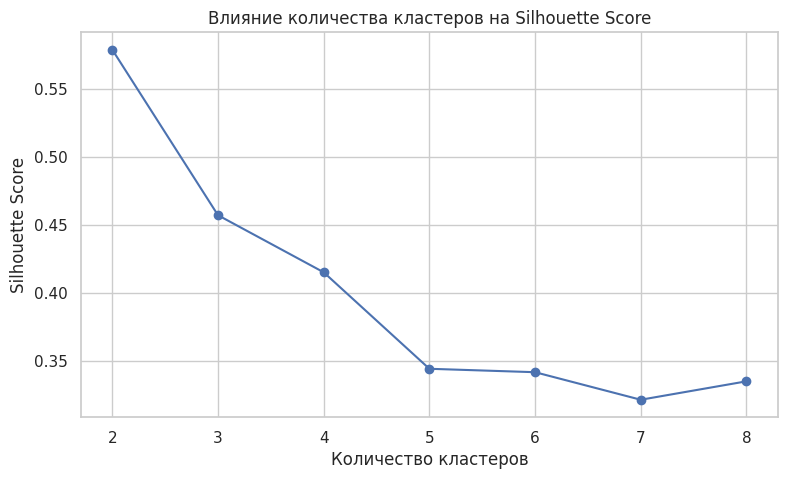

In [217]:
sensitivity = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    sensitivity.append({
        'Количество кластеров': k,
        'Inertia': model.inertia_,
        'Silhouette': silhouette_score(
            X_scaled,
            labels
        ),
        'Calinski-Harabasz': calinski_harabasz_score(
            X_scaled,
            labels
        ),
        'Davies-Bouldin': davies_bouldin_score(
            X_scaled,
            labels
        )
    })

sensitivity_df = pd.DataFrame(sensitivity)

display(sensitivity_df.round(4))

plt.figure(figsize=(9, 5))

plt.plot(
    sensitivity_df['Количество кластеров'],
    sensitivity_df['Silhouette'],
    marker='o'
)

plt.title('Влияние количества кластеров на Silhouette Score')
plt.xlabel('Количество кластеров')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 9))
plt.show()

Значение инерции (Inertia) монотонно убывает с ростом k (с 220.86 при k=2 до 62.11 при k=8). Это объясняется тем, что при увеличении числа центроидов среднее расстояние от точек до центров их кластеров неизбежно сокращается. Наибольший изгиб на графике инерции («локоть») наблюдается при переходе от k=2 к k=3 (падение на 82.6 пункта) и от k=3 к k=4 (падение на 25.35 пункта), после чего скорость снижения инерции заметно замедляется.

Более информативными для выбора k выступают силуэтный коэффициент, индекс Калински-Харабаса и индекс Дэвиса-Булдина. Силуэтный коэффициент, оценивающий баланс между компактностью и разделимостью кластеров, достигает своего глобального максимума при k=2 (0.5792), что подтверждает наличие в данных двух ярко выраженных, хорошо изолированных групп (вид setosa и объединённое облако видов versicolor и virginica). При увеличении k до 3 силуэт существенно снижается до 0.4573, а далее продолжает плавно падать, достигая значений около 0.32–0.34 при k≥5. Значения силуэта ниже 0.4 свидетельствуют о том, что структура кластеров становится слабой и границы между ними сильно размываются.
Аналогичную тенденцию демонстрирует индекс Калински-Харабаса: он максимален при k=2 (241.04), немного снижается при k=3 (234.21) и далее монотонно убывает вплоть до 168.14 при k=8. Это означает, что отношение межкластерной дисперсии к внутрикластерной ухудшается по мере дробления выборки на всё более мелкие группы.

Индекс Дэвиса-Булдина, для которого меньшие значения соответствуют лучшему качеству, также подтверждает этот вывод: его минимум достигается при k=2 (0.5961), тогда как при k≥3 он стабильно растёт, превышая 1.0 при k≥7, что говорит о значительном перекрытии кластеров и потере их обособленности. Небольшой локальный подъём силуэта при k=8 (до 0.3349) на фоне продолжающегося роста индекса Дэвиса-Булдина носит случайный характер дробления плотных областей и не отражает улучшения содержательной структуры.

Дальнейшее увеличение числа кластеров (k≥4) не приводит к улучшению ни одной из метрик и сопровождается лишь искусственным дроблением перекрывающихся групп, поэтому значения k>3 для данного набора данных являются нецелесообразными.


## Заключение

In [218]:
models_data = [
    ('K-means (k=2)', kmeans_labels_2, kmeans_2),
    ('K-means (k=3)', kmeans_labels_3, kmeans_3),
    ('Hierarchical (k=2)', hierarchical_labels_2, None),
    ('Hierarchical (k=3)', hierarchical_labels_3, None)
]

all_metrics = []

for name, labels, model_obj in models_data:

    row = {'Модель': name}

    row['Silhouette'] = silhouette_score(X_scaled, labels)
    row['Calinski-Harabasz'] = calinski_harabasz_score(X_scaled, labels)
    row['Davies-Bouldin'] = davies_bouldin_score(X_scaled, labels)

    row['Rand Index'] = rand_score(y, labels)
    row['ARI'] = adjusted_rand_score(y, labels)
    row['NMI'] = normalized_mutual_info_score(y, labels)
    row['Homogeneity'] = homogeneity_score(y, labels)
    row['Completeness'] = completeness_score(y, labels)
    row['V-measure'] = v_measure_score(y, labels)

    if model_obj is not None and hasattr(model_obj, 'inertia_'):
        row['Inertia'] = model_obj.inertia_
    else:
        row['Inertia'] = np.nan

    unique_labels = np.unique(labels)
    intra_dists = []
    centers = []
    for cl in unique_labels:
        cluster_data = X_scaled[labels == cl]
        center = cluster_data.mean(axis=0)
        centers.append(center)
        dists = np.linalg.norm(cluster_data - center, axis=1)
        intra_dists.append(dists.mean())

    row['Avg Intra-Cluster Dist'] = np.mean(intra_dists)

    from scipy.spatial.distance import pdist
    if len(centers) > 1:
        inter_dists = pdist(np.array(centers))
        row['Avg Inter-Cluster Dist'] = np.mean(inter_dists)
    else:
        row['Avg Inter-Cluster Dist'] = np.nan

    all_metrics.append(row)

final_summary_df = pd.DataFrame(all_metrics)

final_summary_df = final_summary_df.round(4)

print("Итоговая сводная таблица всех метрик качества:")
display(final_summary_df)

Итоговая сводная таблица всех метрик качества:


,Модель,Silhouette,Calinski-Harabasz,Davies-Bouldin,Rand Index,ARI,NMI,Homogeneity,Completeness,V-measure,Inertia,Avg Intra-Cluster Dist,Avg Inter-Cluster Dist
0,K-means (k=2),0.5792,241.0380,0.5961,0.7717,0.5606,0.7302,0.5751,1.0000,0.7302,220.8591,1.0044,3.3701
1,K-means (k=3),0.4573,234.2108,0.8324,0.8323,0.6202,0.6608,0.6605,0.6610,0.6608,138.2577,0.8643,2.9315
2,Hierarchical (k=2),0.5744,230.1508,0.5941,0.7581,0.5359,0.6882,0.5404,0.9472,0.6882,NaN,0.9978,3.3589
3,Hierarchical (k=3),0.4465,216.8003,0.7989,0.8205,0.6049,0.6705,0.6533,0.6886,0.6705,NaN,0.8606,2.8413


1. Сравнительный анализ эффективности методов
Сравнение алгоритмов K-means и иерархической кластеризации (метод Уорда) показывает их высокую согласованность и сопоставимую эффективность на данном наборе данных.
При разбиении на 2 кластера оба метода демонстрируют наилучшие показатели по внутренним метрикам (Silhouette ≈ 0.59), что говорит о формировании двух очень компактных и хорошо разделенных групп. При этом K-means показывает идеальную полноту (Completeness = 1.0), означающую, что объекты одного истинного класса никогда не разделяются между разными кластерами.
При разбиении на 3 кластера метод K-means незначительно, но стабильно превосходит иерархический подход по большинству показателей. Например, скорректированный индекс Рэнда (ARI) у K-means составляет 0.6202 против 0.6049 у иерархического метода, а обычный Rand Index достигает максимума в 0.8323. Это свидетельствует о том, что центроидный подход чуть точнее справляется с задачей разделения частично перекрывающихся классов в евклидовом пространстве. Единственным исключением является индекс Davies-Bouldin при k=3, где иерархический метод показывает чуть лучший результат (0.7989 против 0.8324), формируя несколько более сбалансированные по плотности группы.
2. Интерпретация выделенных кластеров
Анализ центров кластеров и визуализация в пространстве главных компонент (PCA) позволяют дать четкую содержательную интерпретацию выделенным группам, которая полностью совпадает с биологической природой датасета Iris:
Кластер 1 (изолированный): Во всех моделях (и при k=2, и при k=3) устойчиво выделяется отдельная группа, соответствующая виду setosa. Этот кластер характеризуется наименьшими значениями длины и ширины лепестка (в среднем 1.46 см и 0.25 см соответственно) и наибольшей шириной чашелистика (около 3.43 см). Он полностью отделен от остальных объектов пустым пространством в признаковом пространстве.
Кластер 2 и 3 (перекрывающиеся): При k=3 второе облако данных разделяется на виды versicolor и virginica. Центры этих кластеров находятся значительно ближе друг к другу (расстояние около 1.8–1.9 в стандартизированных единицах), чем до центра первого кластера (расстояние более 3.0). Виды различаются преимущественно размером лепестков: у virginica они крупнее (длина в среднем 5.51 см, ширина 1.97 см), чем у versicolor (длина 4.36 см, ширина 1.40 см). Из-за сильного перекрытия этих двух видов в исходном пространстве признаков ни один из методов не способен разделить их идеально (максимальный ARI ≈ 0.67).
3. Выводы о применимости методов к данному типу данных
Исследуемый датасет обладает ярко выраженной групповой (центроидной) структурой с выпуклыми кластерами эллипсоидальной формы.
Для такого типа данных оба рассмотренных метода (K-means и иерархическая кластеризация Уорда) являются высокоэффективными и применимыми. Они успешно выявляют основную структуру данных без необходимости сложной настройки гиперпараметров (кроме выбора k).
Предварительная стандартизация данных (StandardScaler) сыграла критическую роль, позволив алгоритмам, опирающимся на евклидово расстояние, корректно учитывать вклад всех признаков.
Метод K-means показал себя как быстрый, детерминированный (при фиксированном random_state) и дающий слегка более точное соответствие истинной разметке алгоритм для данного случая. Иерархическая кластеризация, в свою очередь, предоставила отличный инструмент для визуального обоснования числа кластеров через дендрограмму и показала сопоставимое качество.
Использование методов, ориентированных на плотность (например, DBSCAN), для данного набора данных было бы менее оправданным без тщательного подбора параметров, так как кластеры имеют разную плотность (setosa очень плотный, остальные более разреженные) и вытянутую форму.
Таким образом, для финального разбиения данных, состоящих из числовых признаков с выпуклой структурой кластеров, целесообразно использовать алгоритм K-means с количеством кластеров k=3, так как он обеспечивает наилучший баланс между внутренней компактностью групп и соответствием реальной структуре объектов.


## Список использованных источников.

1. Iris Dataset : набор данных для кластеризации [Электронный ресурс] // Kaggle : платформа для работы с данными и машинного обучения. — URL: https://www.kaggle.com/datasets/himanshunakrani/iris-dataset (дата обращения: 18.11.2026). — Текст : электронный.

2. Антонянц Е. Н., Искусственный интеллект и машинное обучение : лекция по дисциплине. — Новосибирск : НГТУ НЭТИ, 13 октября 2026 г.